In [1]:
import numpy as np
import matplotlib.pyplot as plt
import fastplotlib as fpl
import scipy
from scipy import linalg
import seaborn as sns
import tifffile
from pathlib import Path

%matplotlib inline

rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [2]:
paths = [
    "/home/kushal/repos/td-svd-sandbox/885D5_MC_rect-1_n-clusters-22.tif",
    "/home/kushal/repos/td-svd-sandbox/885D5_MC_rect-0_n-clusters-10.tif",
    "/home/kushal/repos/td-svd-sandbox/M19D5_MC_rect-1_n-clusters-19.tif",
]

In [3]:
from skimage.transform import downscale_local_mean
from tqdm import tqdm

In [4]:
for path in tqdm(paths):
    movie = tifffile.imread(path)#[:, ::2, ::2]
    
    # Convert the data type to float32
    movie = movie.astype(np.float32)
    
    movie.shape
    
    movie = downscale_local_mean(movie, factors=(1, 2, 2)).copy()
    movie.shape
        
    from skophys.preprocessing import UnVectorizer, Vectorizer
    
    unvec = UnVectorizer(movie.shape[1:])
    vectorizer = Vectorizer()
    X = vectorizer.fit_transform(movie).T
    
    n_pixels = X.shape[1]
    n_time_steps = X.shape[0]
    
    P = np.zeros((n_time_steps-1,n_pixels))
    F = np.zeros((n_time_steps-1,n_pixels))
    for row in range(0,n_time_steps-1):
        P[row,:] = X[row,:]
        F[row,:] = X[row+1,:]
    
    print (f"X.shape = {X.shape}")
    print (f"P.shape = {P.shape}")
    print (f"F.shape = {F.shape}")
    
    def centered_matrix(X):    
        X_mean = X.mean(axis=1, keepdims=True) # has a shape of T x 1
        print (f"X_mean.shape = {X_mean.shape}")
    
        return X - X_mean
    
    Pc = centered_matrix(P)
    Fc = centered_matrix(F)
    
    def eigen_decomposition(M):
        # output eigenvalues and eigenvectors sorted by eigenvalues
        
        eigenvalues, eigenvectors = np.linalg.eig(M)
        eigenvalues = np.real(eigenvalues)
        eigenvectors = np.real(eigenvectors)
        
        sorted_indices = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_indices]
        eigenvectors = eigenvectors[:, sorted_indices]
        print (f"eigenvectors.shape = {eigenvectors.shape}")
    
        return eigenvalues, eigenvectors
    
    def covariance_matrix(X):
        # we assume X has a shape (T,N)
        # N = number of features
        # T = number of samples
        
        N = X.shape[1]
        COV = X.T @ X / float(N)
        
        return COV
    
    def whitened_matrix(X):
        # we assume X has a shape (T,N)
        # N = number of features
        # T = number of samples
        
        COV = covariance_matrix(X)
        S, U = eigen_decomposition(COV)
    
        # Epsilon is added to the eigenvalues to prevent division by zero
        epsilon = 1e-5
        inv_sqrt_S = np.diag(1.0 / np.sqrt(S + epsilon))
    
        # whitening matrix
        W = U @ inv_sqrt_S @ U.T
    
        # whitened data
        Xw = X @ W
    
        return Xw
    
    Pw = whitened_matrix(P)
    Fw = whitened_matrix(F)
    print (f"P.shape = {P.shape}")
    print (f"Pw.shape = {Pw.shape}")
    
    # verify that Pw is whitened data
    COV = covariance_matrix(Pw)
    print (COV)
    
    Z = np.hstack((Pw, Fw))
    ZTZ = Z.T @ Z
    
    k = 16
    
    H_init = 2 * np.sqrt(np.mean(np.mean(ZTZ) / k)) * np.random.rand(ZTZ.shape[0], k)
    
    from tqdm.notebook import tqdm
    
    eta = 5e-1
    error_stop = 1e-4
    error_log = np.zeros(20_000)
    
    Y = H_init.T
    # Y = np.abs(Sk @ Uk.T)
    
    epsilon = 1e-5
    epsilon_mtx = np.ones_like(Y@Y.T@Y) * epsilon
    
    beta = 0.01
    # beta = 1.0
    # beta = 100.300300300300
    for n_iter in tqdm(range(1_000)):
        Y_old = Y.copy()
    
        gamma = Y_old @ ZTZ / (beta * Y_old @ Y_old.T @ Y_old + epsilon_mtx)
        Y = Y_old * (1-eta) + eta * Y_old * gamma
    
        Y = Y.clip(0)  
    
        er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
        error_log[n_iter] = er
        # print (f"er = {er}")
    
        if er < error_stop:
            break
        
    Y1 = Y[:,:n_pixels]
    Y2 = Y[:,n_pixels:]
    
    images = np.zeros((k, *unvec.shape))
    for entry in range(k):
    
        images[entry] = unvec.transform(Y1[entry, :] + Y2[entry, :])

    np.save(f"./ruo_method_{Path(path).stem}.npy", images)

  0%|                                                                                   | 0/3 [00:00<?, ?it/s]/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


X.shape = (19999, 1520)
P.shape = (19998, 1520)
F.shape = (19998, 1520)
X_mean.shape = (19998, 1)
X_mean.shape = (19998, 1)
eigenvectors.shape = (1520, 1520)
eigenvectors.shape = (1520, 1520)
P.shape = (19998, 1520)
Pw.shape = (19998, 1520)
[[ 1.00000000e+00 -7.52842233e-13  2.73605553e-13 ... -9.31886147e-14
   8.77974594e-14 -4.46542255e-13]
 [-7.52842233e-13  1.00000000e+00  9.95743363e-13 ...  4.17471759e-13
   6.23678886e-13 -2.55774203e-14]
 [ 2.73605553e-13  9.95743363e-13  1.00000000e+00 ...  2.72878430e-13
  -1.31872510e-13  9.99434453e-15]
 ...
 [-9.31886147e-14  4.17471759e-13  2.72878430e-13 ...  1.00000000e+00
  -2.23551221e-13  1.08113518e-13]
 [ 8.77974594e-14  6.23678886e-13 -1.31872510e-13 ... -2.23551221e-13
   1.00000000e+00  3.53242435e-13]
 [-4.46542255e-13 -2.55774203e-14  9.99434453e-15 ...  1.08113518e-13
   3.53242435e-13  1.00000000e+00]]


  0%|          | 0/1000 [00:00<?, ?it/s]

 33%|█████████████████████████                                                  | 1/3 [00:31<01:02, 31.30s/it]

X.shape = (19999, 1520)
P.shape = (19998, 1520)
F.shape = (19998, 1520)
X_mean.shape = (19998, 1)
X_mean.shape = (19998, 1)
eigenvectors.shape = (1520, 1520)
eigenvectors.shape = (1520, 1520)
P.shape = (19998, 1520)
Pw.shape = (19998, 1520)
[[ 1.00000000e+00 -3.68800034e-12  9.77765091e-13 ...  8.57476991e-13
   1.82241386e-12 -2.34407230e-13]
 [-3.68800034e-12  1.00000000e+00 -1.92391023e-12 ... -7.23640008e-13
  -6.16246820e-13 -2.93110317e-12]
 [ 9.77765091e-13 -1.92391023e-12  1.00000000e+00 ...  3.07820007e-13
   9.76172067e-13  9.43554043e-13]
 ...
 [ 8.57476991e-13 -7.23640008e-13  3.07820007e-13 ...  1.00000000e+00
  -9.06753284e-12 -1.01580630e-12]
 [ 1.82241386e-12 -6.16246820e-13  9.76172067e-13 ... -9.06753284e-12
   1.00000000e+00 -1.36463034e-12]
 [-2.34407230e-13 -2.93110317e-12  9.43554043e-13 ... -1.01580630e-12
  -1.36463034e-12  1.00000000e+00]]


  0%|          | 0/1000 [00:00<?, ?it/s]

 67%|██████████████████████████████████████████████████                         | 2/3 [00:54<00:26, 26.38s/it]

X.shape = (19999, 756)
P.shape = (19998, 756)
F.shape = (19998, 756)
X_mean.shape = (19998, 1)
X_mean.shape = (19998, 1)
eigenvectors.shape = (756, 756)
eigenvectors.shape = (756, 756)
P.shape = (19998, 756)
Pw.shape = (19998, 756)
[[ 1.00000000e+00  5.22137476e-11  3.67253670e-12 ... -1.55950461e-11
   1.16913198e-12 -2.03381697e-13]
 [ 5.22137476e-11  1.00000000e+00 -1.04920335e-12 ...  7.68933040e-12
  -6.32845253e-12  1.09828027e-12]
 [ 3.67253670e-12 -1.04920335e-12  1.00000000e+00 ...  3.25130274e-12
   4.88041265e-13 -1.84337710e-13]
 ...
 [-1.55950461e-11  7.68933040e-12  3.25130274e-12 ...  1.00000000e+00
  -1.35450908e-12 -4.03937025e-13]
 [ 1.16913198e-12 -6.32845253e-12  4.88041265e-13 ... -1.35450908e-12
   1.00000000e+00 -1.74356708e-13]
 [-2.03381697e-13  1.09828027e-12 -1.84337710e-13 ... -4.03937025e-13
  -1.74356708e-13  1.00000000e+00]]


  0%|          | 0/1000 [00:00<?, ?it/s]

100%|███████████████████████████████████████████████████████████████████████████| 3/3 [01:00<00:00, 20.03s/it]


RFBOutputContext()

JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
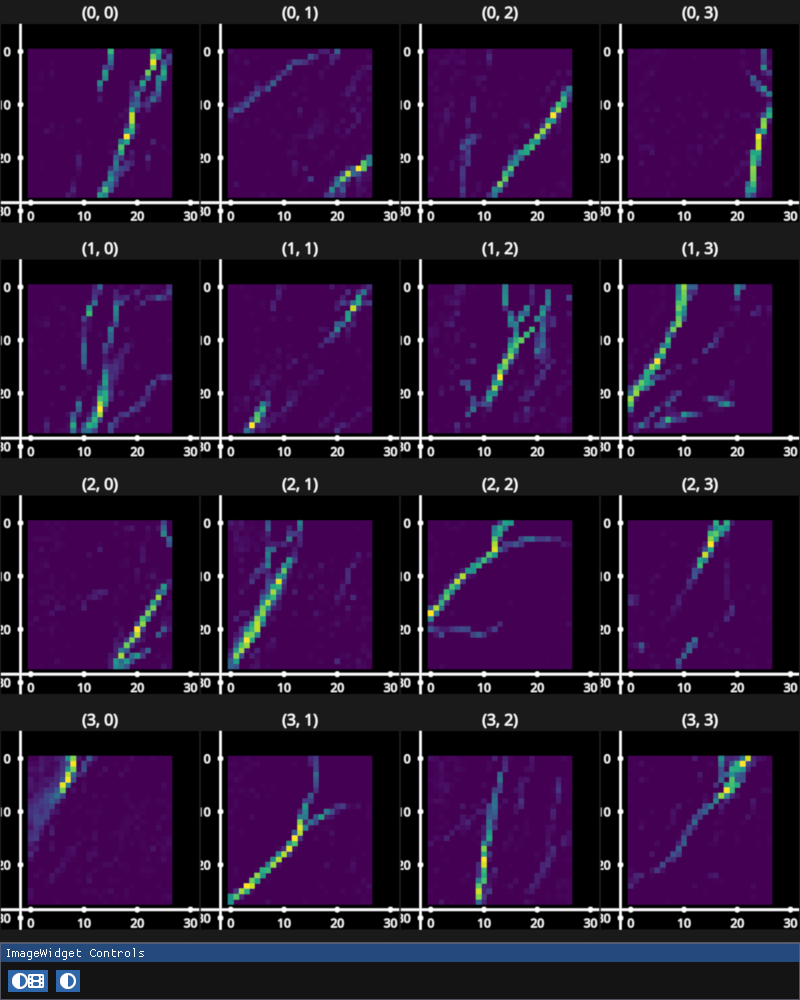

In [7]:
images = np.load("./ruo_method_M19D5_MC_rect-1_n-clusters-19.npy")

iw = fpl.ImageWidget([img for img in images], cmap="viridis", histogram_widget=False, figure_kwargs={"size": (800, 1000)})
for subplot in iw.figure:
    subplot.toolbar = False

iw.show()